# Part 2: Can a neural network tell French from Spanish people by their DNA?

A neural network with one hidden layer, written from scratch with NumPy (forward pass, backpropagation and training loop), trained to classify individuals as French or Spanish from their genotypes.

**Authors:** Ido Shalom, Daniel Rodan

## A neural network from scratch

### Section A

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import matthews_corrcoef

# Ignore warnings
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

In [3]:
# Define the paths to the files
geno_path = 'data/geno_6'
ind_path = 'data/ind_6'

# Load the data
geno = pd.read_csv(geno_path, header=None)
ind = pd.read_csv(ind_path, header=None)

ind.columns = ['Identifier', 'Gender', 'Origin']
ind.Origin = np.array([label.replace('.HO_PCA', '') for label in ind.Origin])

In [4]:
# Initialize a class for the Neural Network
class NeuralNetwork:
    def __init__(self, dataset, labels, middle_layer_dim, learning_rate):
        self.__x = dataset
        self.__y = labels
        self.__middle_layer_dim = middle_layer_dim
        self.__learning_rate = learning_rate

### Section B

$\hat{y} = \sigma (w_2 \cdot \sigma (w_1 \cdot x))$

The dimensions are:

- $\hat{y} \in \mathbb{R}^{N \times 1}$
- $w_1 \in \mathbb{R}^{P \times \text{MidLayerDim}}$
- $w_2 \in \mathbb{R}^{\text{MidLayerDim} \times 1}$


### Section D

In [9]:
# Implement the sigmoid activation function
def sigmoid(z):
    return (1 / (1 + np.exp(-z)))

### Sections C,E,F,G

##### We will write this sections in one chunk, because all of them are functions in the same class

In [10]:
# Sec C - Initialize a class for the Neural Network
class NeuralNetwork:
    def __init__(self, dataset, labels, middle_layer_dim, learning_rate):
        self.x = dataset
        self.__y = labels.reshape(self.x.shape[0], 1)
        self.__middle_layer_dim = middle_layer_dim
        self.__learning_rate = learning_rate
        self.__weights1 = np.random.randn(self.x.shape[1], middle_layer_dim)
        self.__weights2 = np.random.randn(middle_layer_dim, 1)
        self.output = np.zeros(len(labels))

    # Sec E - Calculatation od the prediction of the network, by the weights
    def feedforward(self):
        self.__a1 = sigmoid(np.dot(self.x, self.__weights1))
        self.__a2 = sigmoid(np.dot(self.__a1, self.__weights2))
        self.output = (self.__a2 >= 0.5).astype(int).flatten()

    # Sec F - The backpropagation function
    def backpropagation(self):
        # Gradient for the output layer
        delta2 = 2 * (self.__a2 - self.__y) * self.__a2 * (1 - self.__a2)
        dL_dw2 = np.dot(self.__a1.T, delta2)
        
        # Gradient for the hidden layer
        delta1 = np.dot(delta2, self.__weights2.T) * self.__a1 * (1 - self.__a1)
        dL_dw1 = np.dot(self.x.T, delta1)
        
        # Adjust the network weights
        self.__weights1 -= self.__learning_rate * dL_dw1
        self.__weights2 -= self.__learning_rate * dL_dw2

    # Sec G - Function to train the data
    def train(self, n_simulations=1):
        self.loss_track = np.zeros(n_simulations)
        for i in range(n_simulations):
            self.feedforward()
            self.backpropagation()
            self.loss_track[i] = np.sum((self.__y - self.__a2) ** 2)

### Section H

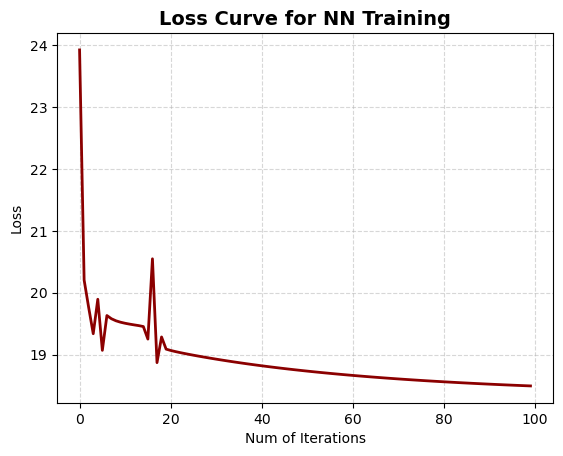

In [18]:
# Instantiate the Neural Network with the dataset
NN = NeuralNetwork(dataset=geno, labels=pd.factorize(ind.Origin)[0], middle_layer_dim=8, learning_rate=0.01)
NN.train(100)

# Visualize the loss progression during training
plt.plot(NN.loss_track, color='darkred', linestyle='-', linewidth=2)
plt.title('Loss Curve for NN Training', fontweight='bold', fontsize=14)
plt.xlabel('Num of Iterations', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Section I

In [19]:
# Define a new class for Neural Network training with a specified train set
class NN_train:
    def __init__(self, dataset, labels, middle_layer_dim, learning_rate, size_train):
        self.__x_train, self.__x_test, self._y_train, self.__y_test = train_test_split(
            dataset, labels, train_size=size_train, random_state=42)
        self.__NN = NeuralNetwork(self.__x_train, self._y_train, middle_layer_dim, learning_rate)

    def train(self, n_simulations):
        self.__NN.train(n_simulations)
        # Compute MCC on the test set
        self.__NN.x = self.__x_test
        self.__NN.feedforward()
        self.test_MCC = matthews_corrcoef(self.__y_test, self.__NN.output)

The Matthews Correlation Coefficient (MCC) is a robust metric for evaluating classification models, offering advantages over traditional loss functions. It handles class imbalance by equally considering true positives, true negatives, false positives, and false negatives, providing a balanced assessment independent of classification thresholds. With values ranging from -1 to +1, MCC facilitates clear model comparisons and captures both sensitivity and specificity. Unlike loss functions that optimize parameters, MCC directly evaluates classification accuracy. Integrating MCC with loss values gives a comprehensive understanding of model performance, tailored to specific data and analytical goals.

### Section J

In [20]:
# Train Neural Networks with different training set sizes
for size in [0.5, 0.75, 0.9]:
    NN_train_size = NN_train(dataset=geno, labels=pd.factorize(ind.Origin)[0], middle_layer_dim=8, learning_rate=0.01, size_train=size)
    NN_train_size.train(100)

    print(f'train size {size} MCC = {NN_train_size.test_MCC}')

train size 0.5 MCC = 0.3211213296902999
train size 0.75 MCC = 0.26226526415648105
train size 0.9 MCC = 0.0


These results indicate that the model performs best with a 50% training set size, achieving a higher MCC score compared to larger training sizes. However, with a 90% training set size, the MCC drops to 0, suggesting potential overfitting or inadequate model learning due to limited training data.